# Pre-class lecture: Python and Jupyter refresher

<p class="lead">
A self-study refresher for the week before the course: how notebooks remember things, the Python values you will meet, lists and dictionaries, pandas DataFrames, summaries, grouped tables and first charts, and how to read an error message. It ends with practice on the penguins data that Activity 1 also uses, with different questions.
</p>

Work through this notebook in order, running each code cell with **Shift + Enter**. It takes about three hours with the practice. You can use either Python route from the [setup page](setup.md):

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder; everything loads from `data/`.
- **Route A (Try JupyterLab):** upload this notebook and `data/penguins.csv`, then change `"data/penguins.csv"` to `"penguins.csv"` in Part 7. Parts 1–6 make their own data and need no files.

---

## What you will be able to do

1. Explain what the **kernel** is and why the order in which cells run matters.
2. Use Python numbers, text, true/false values, lists and dictionaries.
3. Build, load and inspect a pandas **DataFrame**: size, types, missing values, summary statistics.
4. Select, filter, add columns, **group** and **pivot**, and draw a labelled chart.
5. Read a Python error from the bottom up and fix the usual causes.
6. Say which level of the analytics hierarchy a result belongs to before you act on it.

> **How the course uses code**
>
> Most notebooks give you working code. You **read** it, **run** it, **predict** what it will show, then **change** a line or two. Writing long programs from scratch is not the aim; reading output carefully is.

| Part | Topic |
|---|---|
| 1 | Notebooks, cells and the kernel |
| 2 | Python values |
| 3 | Lists and dictionaries |
| 4 | DataFrames with pandas |
| 5 | Describe, group, pivot and plot |
| 6 | Reading errors |
| 7 | Practice on the penguins data (Core, Stretch, Challenge) |
| 8 | Business case, quiz and summary |

> **Reading**
>
> Read Chapter 1 of the course reading packet for the four levels of analytics (descriptive, diagnostic, predictive, prescriptive) and for what `describe()`, `isnull().sum()`, `groupby()` and correlation can and cannot tell you. This notebook practises exactly those calls.

---

## Part 1: Notebooks, cells and the kernel

A notebook is a page of **cells**. A **Markdown** cell holds text like this one. A **code** cell holds Python; when you run it, the result appears underneath.

Behind the page sits the **kernel**: the Python process that actually runs your code and **remembers** every name you have created. The page and the kernel are separate. The page shows what you *typed*; the kernel knows what you *ran*, and in which order.

| You see | It means |
|---|---|
| `[3]` to the left of a cell | This cell was the third one run in this session |
| `[ ]` | Not run yet in this session |
| `[*]` | Running now; wait |
| Kernel status "Idle" | Ready for the next cell |

### Keys to learn first

| Key | Action |
|---|---|
| **Shift + Enter** | Run the cell, move to the next |
| **Esc**, then **A** / **B** | Add a cell above / below |
| **Esc**, then **M** / **Y** | Make the cell Markdown / code |
| **Ctrl + S** (Cmd + S) | Save |

In [1]:
cups_sold = 40
price_per_cup = 18
cups_sold * price_per_cup

720

The last line of a cell is shown automatically. Everything else needs `print(...)`.

> **Predict, then run**
>
> Suppose you scroll up, change `cups_sold = 40` to `cups_sold = 55`, but **do not** run that cell. Then you run the cell below. Which number will it print? Write your guess, try it, then put the value back.

In [2]:
print("The kernel currently remembers cups_sold =", cups_sold)

The kernel currently remembers cups_sold = 40


The kernel only knows what has **run**. Editing a cell changes the page, not the kernel's memory.

> **Misconception: "the notebook runs from top to bottom"**
>
> It does not, unless you make it. You can run cells in any order, and the kernel keeps whatever ran last. A notebook that "worked yesterday" can fail today because, yesterday, cells ran in a different order.
>
> The cure is **Kernel → Restart Kernel and Run All Cells**: Python forgets everything and runs the page top to bottom. Do this before every export or submission, so the PDF shows outputs that match the code.

> **Check your understanding**
>
> A classmate's PDF shows `[7]`, `[3]`, `[12]` beside three consecutive cells. What does that tell you about how the notebook was run, and what should they do before submitting?

---

## Part 2: Python values

Every value has a **type**, and the type decides what you can do with it.

| Type | Example | Used for |
|---|---|---|
| `int` | `42` | Whole numbers: counts |
| `float` | `18.5` | Decimal numbers: prices, measurements |
| `str` | `"Iced tea"` | Text, always in quotes |
| `bool` | `True`, `False` | Answers to yes/no questions |
| `NoneType` | `None` | "No value" |

In [3]:
shop = "Harbour Lane Cafe"
open_days = 7
average_ticket = 23.5
takes_cards = True

print(type(shop), type(open_days), type(average_ticket), type(takes_cards))
print(f"{shop} opens {open_days} days a week; the average ticket is {average_ticket:.2f} currency units.")

<class 'str'> <class 'int'> <class 'float'> <class 'bool'>
Harbour Lane Cafe opens 7 days a week; the average ticket is 23.50 currency units.


An **f-string** (text starting with `f`) puts values into text inside `{ }`; `:.2f` shows two decimals.

### Comparisons give `True` or `False`

One `=` **stores** a value. Two, `==`, **asks** whether two values are equal. Filters in pandas are built from exactly these questions.

In [4]:
print(open_days == 6)        # a question: is it 6?
print(average_ticket > 25)   # is it above 25?
print(takes_cards and open_days >= 5)

False
False
True


> **Predict, then run: text that looks like a number**
>
> `"3"` is text and `3` is a number. What happens when you add `"3" + "4"`? What about `int("3") + 4`? Guess both, then run.

In [5]:
print("3" + "4")       # joining two pieces of text
print(int("3") + 4)    # converting text to a number first

34
7


Joining text is not arithmetic. When a column of numbers has been read as text (one stray letter is enough), sums and means fail or behave strangely, so always check the types of a new table.

> **Misconception: "the computer does exact decimal arithmetic"**
>
> Decimals are stored in binary, so tiny rounding gaps appear. Run the next cell. This never matters for business reporting as long as you **round when you display**, and never test decimals with `==`.

In [6]:
print(0.1 + 0.2)
print(round(0.1 + 0.2, 2))

0.30000000000000004
0.3


---

## Part 3: Lists and dictionaries

A **list** holds values in order, inside `[ ]`. Positions count from **0**, and `-1` means the last one. A **slice** `[a:b]` takes positions `a` up to, but not including, `b`.

In [7]:
weekly_cups = [210, 185, 240, 260, 198, 305]   # six weeks
print("First week:", weekly_cups[0])
print("Last week:", weekly_cups[-1])
print("Weeks 2 to 4:", weekly_cups[1:4])
print("Total:", sum(weekly_cups), "| weeks:", len(weekly_cups), "| average:", round(sum(weekly_cups) / len(weekly_cups), 1))

First week: 210
Last week: 305
Weeks 2 to 4: [185, 240, 260]
Total: 1398 | weeks: 6 | average: 233.0


A **dictionary** pairs **keys** with **values**, inside `{ }`, so you look things up by name instead of by position.

In [8]:
menu = {"Latte": 18, "Iced tea": 15, "Hot chocolate": 16}
print("Price of iced tea:", menu["Iced tea"])
menu["Lemonade"] = 14          # add an item
print("Items:", list(menu))
print("Cheapest first:", sorted(menu, key=menu.get))

Price of iced tea: 15
Items: ['Latte', 'Iced tea', 'Hot chocolate', 'Lemonade']
Cheapest first: ['Lemonade', 'Iced tea', 'Hot chocolate', 'Latte']


A table is just these two ideas combined: a **list of rows**, where each row is a **dictionary** of column values. pandas turns that into a DataFrame in one step.

In [9]:
import pandas as pd

rows = [
    {"drink": "Latte", "cups": 31, "price": 18},
    {"drink": "Iced tea", "cups": 22, "price": 15},
    {"drink": "Hot chocolate", "cups": 9, "price": 16},
]
small = pd.DataFrame(rows)
small["revenue"] = small["cups"] * small["price"]
small

,drink,cups,price,revenue
0,Latte,31,18,558
1,Iced tea,22,15,330
2,Hot chocolate,9,16,144


> **Check your understanding**
>
> 1. What does `weekly_cups[2]` return, and why is it not `185`?
> 2. In the `small` table, what does **one row** represent? (This is the table's **grain**, and it decides what counting means.)

---

## Part 4: DataFrames with pandas

To practise on something bigger without touching any graded dataset, the next cell **generates** six weeks of sales for an imaginary café: one row per drink per day. The data is **synthetic** (made up by a seeded random generator, so it is identical every time). Money is in neutral **currency units**.

In [10]:
import numpy as np

rng = np.random.default_rng(2026)
dates = pd.date_range("2026-09-07", periods=42, freq="D")   # six weeks, Monday to Sunday
temperature = np.round(rng.normal(24, 4, len(dates)), 1)     # daily high, degrees Celsius
prices = {"Latte": 18, "Iced tea": 15, "Hot chocolate": 16}

records = []
for day, temp in zip(dates, temperature):
    weekend = day.dayofweek >= 5
    base = {"Latte": 30, "Iced tea": 6 + 1.6 * (temp - 18), "Hot chocolate": 22 - 0.9 * (temp - 18)}
    for drink, mean_cups in base.items():
        mean_cups = max(mean_cups, 2) * (1.4 if weekend else 1.0)
        records.append({
            "date": day,
            "weekday": day.day_name(),
            "weekend": weekend,
            "temp_c": temp,
            "drink": drink,
            "cups": int(rng.poisson(mean_cups)),
            "price": prices[drink],
        })

cafe = pd.DataFrame(records)
cafe.loc[[17, 88], "cups"] = np.nan   # two days where the till record was lost
cafe.head()

,date,weekday,weekend,temp_c,drink,cups,price
0,2026-09-07,Monday,False,20.8,Latte,25.0,18
1,2026-09-07,Monday,False,20.8,Iced tea,11.0,15
2,2026-09-07,Monday,False,20.8,Hot chocolate,23.0,16
3,2026-09-08,Tuesday,False,25.0,Latte,32.0,18
4,2026-09-08,Tuesday,False,25.0,Iced tea,16.0,15


### First look: size, types and missing values

Four questions to ask of **every** new table, in this order:

1. How big is it? `shape`
2. What type is each column? `dtypes`
3. Where is data missing? `isnull().sum()`
4. What do the numbers look like? `describe()`

In [11]:
print("Rows, columns:", cafe.shape)
print()
print(cafe.dtypes)

Rows, columns: (126, 7)

date       datetime64[ns]
weekday            object
weekend              bool
temp_c            float64
drink              object
cups              float64
price               int64
dtype: object


`int64` is whole numbers, `float64` decimals, `object` text, `bool` true/false and `datetime64` dates. Notice that `cups` is `float64` although cups are whole: pandas stores a missing number as `NaN` ("not a number"), which is a float, so the whole column becomes float.

In [12]:
cafe.isnull().sum()

date       0
weekday    0
weekend    0
temp_c     0
drink      0
cups       2
price      0
dtype: int64

In [13]:
cafe.describe().round(1)

,date,temp_c,cups,price
count,126,126.0,124.0,126.0
mean,2026-09-27 12:00:00,24.2,23.0,16.3
min,2026-09-07 00:00:00,16.4,0.0,15.0
25%,2026-09-17 00:00:00,22.1,16.0,15.0
50%,2026-09-27 12:00:00,23.7,22.0,16.0
75%,2026-10-08 00:00:00,26.6,29.0,18.0
max,2026-10-18 00:00:00,31.3,56.0,18.0
std,NaN,3.2,10.0,1.3


> **Predict, then run**
>
> The table has 126 rows. What will the **count** row of `describe()` show for `cups`, and why? Check your prediction against the output above.

`describe()` silently **skips** missing values. The mean of `cups` is a real number, but it describes fewer rows than the table holds. That is why `isnull().sum()` comes first.

> **Misconception: "a missing value is zero"**
>
> A lost till record does not mean nobody bought a drink. Filling `NaN` with 0 would drag every average down. In this course a missing value is **not available**, never 0, unless you have evidence it really was zero.

### Select, filter, sort and add columns

In [14]:
cafe[["date", "drink", "cups"]].head(3)       # several columns: a list inside the brackets

,date,drink,cups
0,2026-09-07,Latte,25.0
1,2026-09-07,Iced tea,11.0
2,2026-09-07,Hot chocolate,23.0


In [15]:
hot_weekends = cafe[(cafe["temp_c"] >= 28) & (cafe["weekend"])]
print("Rows on hot weekend days:", len(hot_weekends))

cafe["revenue"] = cafe["cups"] * cafe["price"]
cafe.sort_values("revenue", ascending=False).head(3)[["date", "weekday", "drink", "temp_c", "revenue"]]

Rows on hot weekend days: 6


,date,weekday,drink,temp_c,revenue
15,2026-09-12,Saturday,Latte,22.8,1008.0
39,2026-09-20,Sunday,Latte,23.7,918.0
120,2026-10-17,Saturday,Latte,24.8,882.0


Conditions go in their own brackets and are joined with `&` (and) or `|` (or). A new column is calculated row by row; where `cups` is missing, `revenue` is missing too, which is correct.

> **Check your understanding**
>
> Write a filter that keeps only **Latte** rows on **weekdays**. Which two conditions do you combine, and with which symbol?

---

## Part 5: Describe, group, pivot and plot

### Grouped summaries

An overall average blends groups that may behave very differently. `groupby` splits the table into groups and summarises each one. Each line inside `agg` reads *new name = (column, summary)*.

In [16]:
by_drink = cafe.groupby("drink").agg(
    days=("cups", "count"),
    average_cups=("cups", "mean"),
    total_revenue=("revenue", "sum"),
).round(1)
by_drink

,days,average_cups,total_revenue
drink,,,
Hot chocolate,41,18.7,12240.0
Iced tea,41,17.8,10950.0
Latte,42,32.5,24534.0


The `days` column counts **non-missing** values, so it shows directly where the two lost records were.

### Pivot tables

A **pivot table** puts one category down the side and another across the top, like a pivot table in Excel.

In [17]:
cafe["weather"] = np.where(cafe["temp_c"] >= 25, "Warm (25 °C or more)", "Cool (below 25 °C)")
pd.pivot_table(cafe, index="drink", columns="weather", values="cups", aggfunc="mean").round(1)

weather,Cool (below 25 °C),Warm (25 °C or more)
drink,,
Hot chocolate,21.8,14.2
Iced tea,15.0,21.7
Latte,32.9,31.8


> **Predict, then run**
>
> Before looking closely at the pivot table: which drink do you expect to sell **more** on warm days and which **less**? Now check. Does any drink barely change?

### Charts

A chart needs a **title** that states the message, **labelled axes with units**, and ends with `plt.show()`. Choose the chart for the question:

| Question | Chart |
|---|---|
| How is one number spread out? | Histogram |
| How do groups compare? | Bar chart |
| Do two numbers move together? | Scatter plot |
| How does a number change over time? | Line chart |

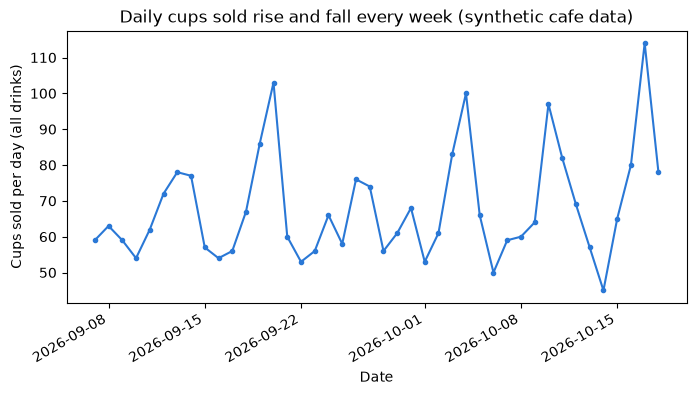

In [18]:
import matplotlib.pyplot as plt

daily = cafe.groupby("date").agg(cups=("cups", "sum"), temp_c=("temp_c", "first"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(daily.index, daily["cups"], color="#2a78d6", marker="o", markersize=3)
ax.set_title("Daily cups sold rise and fall every week (synthetic cafe data)")
ax.set_xlabel("Date")
ax.set_ylabel("Cups sold per day (all drinks)")
fig.autofmt_xdate()
plt.show()

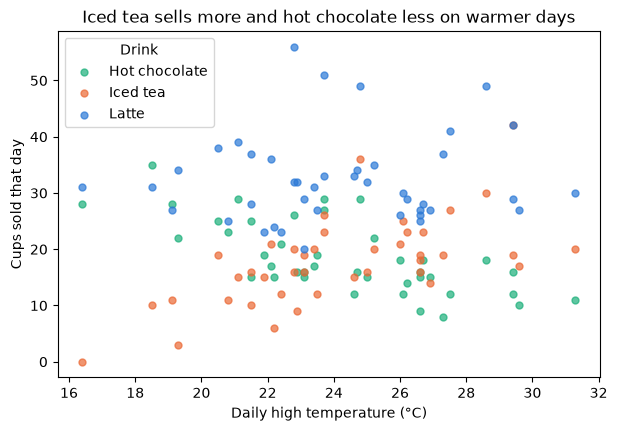

In [19]:
colours = {"Latte": "#2a78d6", "Iced tea": "#eb6834", "Hot chocolate": "#1baf7a"}

fig, ax = plt.subplots(figsize=(7, 4.5))
for drink, group in cafe.groupby("drink"):
    ax.scatter(group["temp_c"], group["cups"], label=drink, color=colours[drink], alpha=0.7, s=25)
ax.set_title("Iced tea sells more and hot chocolate less on warmer days")
ax.set_xlabel("Daily high temperature (°C)")
ax.set_ylabel("Cups sold that day")
ax.legend(title="Drink")
plt.show()

### Correlation, and what it does not show

The **correlation coefficient** *r* runs from −1 to +1 and measures how closely two numbers move together along a straight line.

In [20]:
for drink, group in cafe.groupby("drink"):
    r = group["temp_c"].corr(group["cups"])
    print(f"{drink:<14} r(temperature, cups) = {r:+.2f}")

Hot chocolate  r(temperature, cups) = -0.69
Iced tea       r(temperature, cups) = +0.63
Latte          r(temperature, cups) = +0.07


> **From statistic to insight: a worked example**
>
> The manager asks: *"Should we prepare more iced tea on warm days?"*
>
> 1. **Descriptive** (what happened): the pivot table and the scatter plot show iced tea sales were higher on warm days in these six weeks.
> 2. **Diagnostic** (why): warmer weather is a plausible reason, but weekends also lift sales. If warm days happened to fall on weekends, part of the "temperature effect" would really be a weekend effect. Check by comparing warm and cool days **within** weekdays only.
> 3. **Predictive** (what next): tomorrow's forecast high could be used to estimate tomorrow's iced tea sales.
> 4. **Prescriptive** (what to do): prepare more iced tea when the forecast is warm, and less hot chocolate, then measure whether waste falls.
>
> The numbers above only answer step 1. Each later step needs more work, and that is the path this course follows.

In [21]:
weekdays_only = cafe[~cafe["weekend"]]
pd.pivot_table(weekdays_only, index="drink", columns="weather", values="cups", aggfunc="mean").round(1)

weather,Cool (below 25 °C),Warm (25 °C or more)
drink,,
Hot chocolate,18.8,13.8
Iced tea,11.4,19.8
Latte,28.1,29.9


> **Misconception: "a strong correlation proves one thing causes the other"**
>
> Correlation describes how two columns moved together in **this** data. A third factor (here, the weekend) can push both, and a categorical factor never appears in a correlation at all because it is not a number. Always ask what else changed at the same time.

> **Check your understanding**
>
> Compare the weekday-only pivot table with the full one. Does the warm-versus-cool difference for iced tea survive when weekends are removed? What does your answer say about the manager's question?

---

## Part 6: Reading errors

Errors are normal and informative. A Python error message (a **traceback**) reads from the **bottom up**:

1. The **last line** names the error type and the problem.
2. The lines above show **where** it happened; the arrow points to the line in your cell.

Normally an error stops the cell. So that this page runs without stopping, the next cells **catch** each error and print its last line, which is exactly the line you would read first.

In [22]:
try:
    cafe["Cups"].mean()            # capital C
except KeyError as error:
    print("KeyError:", error)
print("The real column names are:", list(cafe.columns))

KeyError: 'Cups'
The real column names are: ['date', 'weekday', 'weekend', 'temp_c', 'drink', 'cups', 'price', 'revenue', 'weather']


In [23]:
try:
    "Revenue: " + 250
except TypeError as error:
    print("TypeError:", error)
print("Fixed:", "Revenue: " + str(250))

TypeError: can only concatenate str (not "int") to str
Fixed: Revenue: 250


In [24]:
try:
    pd.read_csv("data/penguin.csv")      # missing an 's'
except FileNotFoundError as error:
    print("FileNotFoundError:", error)

FileNotFoundError: [Errno 2] No such file or directory: 'data/penguin.csv'


| Error (last line) | Usual cause | Fix |
|---|---|---|
| `NameError: name 'x' is not defined` | The cell that creates `x` has not run in this session | Run the earlier cells, or restart and run all |
| `KeyError: 'Cups'` | A column or key spelled differently; capitals count | Check `df.columns` and copy the exact name |
| `TypeError: can only concatenate str …` | Mixing text and numbers | Convert with `str()`, `int()` or `float()` |
| `SyntaxError` | A missing bracket, quote or comma | Look at the line the caret `^` points to |
| `FileNotFoundError` | Wrong file name, or the notebook is not next to `data` | Check the spelling; save the notebook in `DATA300_GAP` |
| `ModuleNotFoundError` | The package is not installed in this session | Route A: run the `%pip install` cell. Route B: tell your facilitator |

> **Warnings are not errors**
>
> A pink box that starts with `FutureWarning` or `UserWarning` is advice, and the cell still ran. Read it, but do not panic.

---

## Part 7: Practice on the penguins data

The Palmer Penguins data records 344 penguins of three species on three islands in Antarctica. Activity 1 uses it too, but **these questions are different**: they are about missing data, counts and bills, not the Activity 1 questions.

Each practice cell already contains **working code**. Run it, answer the question in a sentence, then change the code as suggested.

### Core

In [25]:
penguins = pd.read_csv("data/penguins.csv")   # Route A: "penguins.csv"
print("Rows, columns:", penguins.shape)
penguins.isnull().sum()

Rows, columns: (344, 7)


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

**Core 1.** Which columns have missing values? Why might `sex` be missing more often than the measurements? Then look at the rows with a missing bill length (`penguins[penguins["bill_length_mm"].isnull()]`): what else is missing in them?

In [26]:
pd.crosstab(penguins["island"], penguins["species"])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


**Core 2.** The table counts penguins by island and species. Which species was found on more than one island? Which island has only one species? Why would that matter if someone compared the islands' average bill length?

In [27]:
penguins[["bill_length_mm", "bill_depth_mm"]].describe().round(1)

,bill_length_mm,bill_depth_mm
count,342.0,342.0
mean,43.9,17.2
std,5.5,2.0
min,32.1,13.1
25%,39.2,15.6
50%,44.4,17.3
75%,48.5,18.7
max,59.6,21.5


**Core 3.** Read the summary of the two bill measurements. What is the unit? Is the range (min to max) of bill length wider or narrower than of bill depth? Change the code to describe `flipper_length_mm` instead.

### Stretch

In [28]:
penguins.groupby("species").agg(
    measured=("bill_length_mm", "count"),
    mean_bill_length=("bill_length_mm", "mean"),
    mean_bill_depth=("bill_depth_mm", "mean"),
).round(1)

,measured,mean_bill_length,mean_bill_depth
species,,,
Adelie,151,38.8,18.3
Chinstrap,68,48.8,18.4
Gentoo,123,47.5,15.0


**Stretch 1.** Which species has the longest bills on average, and which the deepest? Add a line to `agg` for the **median** bill length (`"median"`). Are mean and median close? What would it mean if they were far apart?

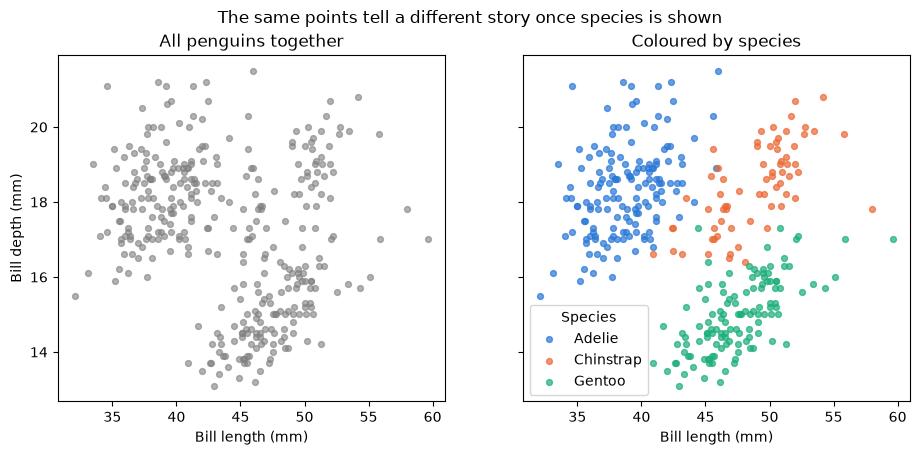

r for all penguins together: -0.24


In [29]:
species_colours = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
axes[0].scatter(penguins["bill_length_mm"], penguins["bill_depth_mm"], color="grey", alpha=0.6, s=18)
axes[0].set_title("All penguins together")
for species, group in penguins.groupby("species"):
    axes[1].scatter(group["bill_length_mm"], group["bill_depth_mm"], color=species_colours[species],
                    label=species, alpha=0.7, s=18)
axes[1].set_title("Coloured by species")
axes[1].legend(title="Species")
for ax in axes:
    ax.set_xlabel("Bill length (mm)")
axes[0].set_ylabel("Bill depth (mm)")
fig.suptitle("The same points tell a different story once species is shown")
plt.show()

print(f"r for all penguins together: {penguins['bill_length_mm'].corr(penguins['bill_depth_mm']):+.2f}")

**Stretch 2.** Describe the trend in the left chart in one sentence, then in the right chart. Calculate *r* **within** each species (copy the correlation loop from Part 5 and change the names). Why can the overall *r* point one way while every species points the other? Which factor was hidden?

### Challenge

In [30]:
penguins["bill_ratio"] = penguins["bill_length_mm"] / penguins["bill_depth_mm"]
pd.pivot_table(penguins, index="species", columns="sex", values="bill_ratio", aggfunc="mean").round(2)

sex,FEMALE,MALE
species,,
Adelie,2.12,2.12
Chinstrap,2.65,2.66
Gentoo,3.20,3.15


**Challenge 1.** A new column divides bill length by bill depth (a shape measure with no unit). Does the ratio separate the species more clearly than either measurement alone? Draw a histogram of `bill_ratio` with one colour per species to check, with a title and labelled axes.

**Challenge 2.** Write a short paragraph for a field-station manager who must decide which measurements to keep recording next season. Which descriptive results support your advice, and what would you need beyond description (diagnostic or predictive work) before you were confident?

---

## Part 8: Business case, quiz and summary

### Business case for discussion: the two tea shops

A tea chain's regional manager sees that **Shop A**'s average order value last month was clearly higher than **Shop B**'s, and proposes copying Shop A's staff training at Shop B.

Discuss before the course (or in the first lecture):

1. What is the **grain** of the data behind "average order value"? One row per order, per item, per day?
2. Shop A is in an office district and Shop B near a university. Name a **confounding** factor that could explain the gap without any difference in training.
3. Shop B's till lost three days of records. How could that bias the comparison, and what would you check first?
4. Which level of the analytics hierarchy does the manager's evidence belong to, and which level does the proposal need?
5. Design a fairer comparison: which groups or columns would you put in a pivot table?

### Quiz

1. You edit a cell but do not run it, then run the next cell. Which value does Python use, and why?
2. What is the difference between `x = 5` and `x == 5`?
3. What does `cafe.isnull().sum()` tell you that `cafe.describe()` does not?
4. Write the code for the average `cups` per `weekday` in the café table.
5. A correlation of +0.8 between ice-cream sales and sunburn cases is found. Give a factor that could drive both.
6. Read this last line of an error and say what you would do: `KeyError: 'Body_Mass_g'`.

---

## Quick reference

| You want to… | Code |
|---|---|
| Load a CSV | `df = pd.read_csv("data/file.csv")` |
| Size, types, first rows | `df.shape`, `df.dtypes`, `df.head()` |
| Missing values per column | `df.isnull().sum()` |
| Summary statistics | `df.describe()` |
| Columns | `df["col"]`, `df[["a", "b"]]` |
| Filter rows | `df[(df["a"] > 5) & (df["b"] == "x")]` |
| New column | `df["c"] = df["a"] * df["b"]` |
| Count values / cross-tabulate | `df["col"].value_counts()`, `pd.crosstab(df["a"], df["b"])` |
| Grouped summary | `df.groupby("g").agg(new=("col", "mean"))` |
| Pivot table | `pd.pivot_table(df, index="a", columns="b", values="v", aggfunc="mean")` |
| Correlation | `df["a"].corr(df["b"])` |
| Chart | `fig, ax = plt.subplots()` … `ax.set_title(...)` … `plt.show()` |

## Summary

- The kernel remembers what **ran**, not what is written. Restart and run all before exporting.
- Types matter: text that looks like a number is still text; decimals need rounding for display.
- Lists are ordered, dictionaries are looked up by name; a table is a list of row dictionaries.
- For any new table: `shape`, `dtypes`, `isnull().sum()`, then `describe()`. Missing is not zero.
- `groupby` and pivot tables compare groups; charts need a message title and labelled axes.
- Correlation is description. Before acting, ask what else could explain the pattern.
- Read errors from the bottom line up.

---

## Next: Activity 1

The [Activity 1 guide](guides/activity1_readiness.md) explains the graded readiness check: running a given analysis of the penguins data and making two Tableau charts. It is due **Monday 9 November, 23:59 China Standard Time**.

---

## For the facilitator

This notebook is pre-class self-study. If a group needs a catch-up session on Day 1 or in an evening, it fits four periods as below. No answers are given here.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| 1 | 45 | Part 1 (kernel and run order) and Part 2 (values) | Do the run-order prediction live; let a cell fail on purpose, then restart and run all |
| 2 | 45 | Part 3 (lists, dictionaries) and Part 4 (DataFrames, missing values) | Stress the four first-look questions; ask why `cups` is a float |
| 3 | 45 | Part 5 (group, pivot, chart, correlation) and Part 6 (errors) | Use the iced-tea worked example to walk the analytics hierarchy; let students read the error lines aloud |
| 4 | 45 | Part 7 practice (Core for all, Stretch and Challenge for faster students) and the tea-shop case | Discuss the bill length and depth charts as a first look at confounding; leave five minutes for the quiz |

Students on Route A need `penguins.csv` uploaded into Try JupyterLab before Part 7. Do not discuss the Activity 1 questions themselves.